# STURM-Flood — Sentinel-1 U-Net Baseline (Google Colab / T4)

This notebook trains a **Sentinel-1-only semantic segmentation baseline** on STURM-Flood. It is designed to be run cell-by-cell in Colab.

**Paper-aligned setup:** 128×128 tiles, VV/VH (2 channels), binary classes (non-water=0, water=1), min–max scaling based on Sentinel-1 range −30 to 10 when input TIFFs contain dB values, random 80/10/10 train/validation/test split, U-Net, Adam, focal loss (α=0.25, γ=2).

**T4 note:** the paper's tuned model is very large (~34.5M parameters, 64 starting filters, 6 blocks, batch size 64). To reduce GPU out-of-memory risk, this notebook defaults to 32 starting filters, 5 blocks and batch size 4. This is a practical baseline, **not an exact reproduction of the paper's best tuned configuration**. You can increase these after a successful run.

**Important:** never use the test set for tuning. Results from this run are your experimental results, not the paper's reported results.

## Cell 1 — Enable GPU
In Colab, select **Runtime → Change runtime type → T4 GPU**, then run:

In [4]:
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Cell 2 — Mount Google Drive and set dataset paths
Expected dataset structure from the paper/repository: `Dataset/Sentinel1/S1` and `Dataset/Sentinel1/Floodmaps`. Update `DATA_ROOT` if your folder is elsewhere.

In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

# Based on your current Google Drive screenshot:
ZIP_PATH = "/content/drive/MyDrive/Dataset/Dataset.zip"

# Extracted files are kept in Colab temporary storage to avoid a second Drive copy.
EXTRACT_DIR = "/content/sturm_dataset"
DATA_ROOT = os.path.join(EXTRACT_DIR, "Dataset")

if not os.path.isdir(DATA_ROOT):
    if not os.path.isfile(ZIP_PATH):
        raise FileNotFoundError(
            f"Dataset ZIP not found at {ZIP_PATH}. Check Google Drive path."
        )
    print("Extracting dataset. This may take a while...")
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(EXTRACT_DIR)
    print("Extraction completed.")

S1_IMAGE_DIR = os.path.join(DATA_ROOT, "Sentinel1", "S1")
S1_MASK_DIR = os.path.join(DATA_ROOT, "Sentinel1", "Floodmaps")

print("Dataset root exists:", os.path.isdir(DATA_ROOT))
print("Sentinel-1 image directory:", S1_IMAGE_DIR, os.path.isdir(S1_IMAGE_DIR))
print("Sentinel-1 mask directory:", S1_MASK_DIR, os.path.isdir(S1_MASK_DIR))

if not os.path.isdir(S1_IMAGE_DIR):
    candidates = []
    for root, dirs, files in os.walk(os.path.join(DATA_ROOT, "Sentinel1")):
        if any(f.lower().endswith((".tif", ".tiff")) for f in files):
            candidates.append(root)
    print("Folders containing TIFFs under Sentinel1:", candidates[:20])
    raise FileNotFoundError(
        "Expected Sentinel1/S1 image folder was not found. "
        "Use the printed folder list to update S1_IMAGE_DIR."
    )

if not os.path.isdir(S1_MASK_DIR):
    raise FileNotFoundError("Sentinel1/Floodmaps mask folder was not found.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset root exists: True
Sentinel-1 image directory: /content/sturm_dataset/Dataset/Sentinel1/S1 True
Sentinel-1 mask directory: /content/sturm_dataset/Dataset/Sentinel1/Floodmaps True


## Cell 3 — Install/import dependencies

In [6]:
!pip -q install rasterio scikit-learn pandas matplotlib

In [7]:
import glob, random, math, json, time
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    jaccard_score, confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Reduce the chance of T4 memory spikes.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory-growth setting skipped:", e)

## Cell 4 — Find and pair image/mask GeoTIFFs

This matches tiles by filename stem rather than relying on file order. It reports unmatched files and verifies tile dimensions/band counts on the first samples.

In [10]:
def tif_map(folder):
    paths = glob.glob(os.path.join(folder, "**", "*.tif"), recursive=True)
    # Map by basename; if duplicate basenames exist, keep the first and report count.
    result = {}
    for p in sorted(paths):
        result.setdefault(os.path.basename(p), p)
    return result

image_map = tif_map(S1_IMAGE_DIR)
mask_map  = tif_map(S1_MASK_DIR)
common_names = sorted(set(image_map) & set(mask_map))

print("Image TIFFs:", len(image_map))
print("Mask TIFFs:", len(mask_map))
print("Matched pairs:", len(common_names))
print("Unmatched images:", len(set(image_map) - set(mask_map)))
print("Unmatched masks:", len(set(mask_map) - set(image_map)))
assert len(common_names) > 0, "No image-mask pairs found. Check folder paths and matching filenames."

def raster_info(path):
    with rasterio.open(path) as src:
        return {"path": path, "shape": (src.height, src.width), "bands": src.count,
                "dtype": src.dtypes, "min": src.read().min(), "max": src.read().max(),
                "nodata": src.nodata}

for name in common_names[:3]:
    print("\n", name)
    print("IMAGE:", raster_info(image_map[name]))
    print("MASK :", raster_info(mask_map[name]))

Image TIFFs: 5928
Mask TIFFs: 21602
Matched pairs: 5928
Unmatched images: 0
Unmatched masks: 15674

 EMSR260_02VIADANA_2_1_2_2.tif
IMAGE: {'path': '/content/sturm_dataset/Dataset/Sentinel1/S1/EMSR260_02VIADANA_2_1_2_2.tif', 'shape': (128, 128), 'bands': 2, 'dtype': ('float32', 'float32'), 'min': np.float32(-0.14516059), 'max': np.float32(0.8355912), 'nodata': 0.0}
MASK : {'path': '/content/sturm_dataset/Dataset/Sentinel1/Floodmaps/EMSR260_02VIADANA_2_1_2_2.tif', 'shape': (128, 128), 'bands': 1, 'dtype': ('uint8',), 'min': np.uint8(0), 'max': np.uint8(5), 'nodata': 99.0}

 EMSR260_02VIADANA_2_2_2_1.tif
IMAGE: {'path': '/content/sturm_dataset/Dataset/Sentinel1/S1/EMSR260_02VIADANA_2_2_2_1.tif', 'shape': (128, 128), 'bands': 2, 'dtype': ('float32', 'float32'), 'min': np.float32(-0.12607078), 'max': np.float32(1.0817064), 'nodata': 0.0}
MASK : {'path': '/content/sturm_dataset/Dataset/Sentinel1/Floodmaps/EMSR260_02VIADANA_2_2_2_1.tif', 'shape': (128, 128), 'bands': 1, 'dtype': ('uint8',), '

## Cell 5 — Set experiment configuration

If Cell 4 shows that image values are already normalized (for example approximately 0–1), keep `NORMALIZE_DB_RANGE=False`. If the values are Sentinel-1 dB values around −30 to 10, set it to `True` to apply the paper's min–max scaling. **Do not normalize twice.**

The mask mapping assumes original STURM labels: 0 = non-water; 1–5 = water-related classes; 99 = no-data. Any other label values are reported and should be investigated before training.

In [22]:
TILE_SIZE = 128
N_CHANNELS = 2
N_CLASSES = 2

# Inspect a few image tiles first. Set this based on the printed min/max values.
NORMALIZE_DB_RANGE = False  # True for dB inputs in roughly [-30, 10]; False if already scaled.

# T4-friendly defaults. Raise filters/batch only after a successful first run.
START_FILTERS = 32
N_BLOCKS = 5  # T4-friendly; paper best model used 6 blocks
BATCH_SIZE = 4
EPOCHS = 20
LEARNING_RATE = 1e-3
DROPOUT = 0.30
WEIGHT_DECAY = 1e-4
AUTOTUNE = tf.data.AUTOTUNE

# Optional quick smoke test: set to e.g. 1000 for a fast pipeline test, or None for all pairs.
MAX_PAIRS = None

if MAX_PAIRS is not None:
    common_names = common_names[:MAX_PAIRS]

print("Pairs to process:", len(common_names))

Pairs to process: 5928


In [23]:
# Check image values after correcting normalization

NORMALIZE_DB_RANGE = False

sample_name = common_names[0]

sample_image = read_s1_image(
    image_map[sample_name]
)

print("Image shape:", sample_image.shape)
print("Minimum:", sample_image.min())
print("Maximum:", sample_image.max())
print("Mean:", sample_image.mean())
print("Standard deviation:", sample_image.std())

print("\nBand-wise statistics:")

for i, band in enumerate(["VV", "VH"]):
    print(
        band,
        "Min:", sample_image[..., i].min(),
        "Max:", sample_image[..., i].max(),
        "Mean:", sample_image[..., i].mean()
    )

Image shape: (128, 128, 2)
Minimum: -0.14516059
Maximum: 0.8355912
Mean: 0.3953839
Standard deviation: 0.13891786

Band-wise statistics:
VV Min: 0.11230688 Max: 0.8355912 Mean: 0.47518998
VH Min: -0.14516059 Max: 0.5789371 Mean: 0.3155778


In [24]:
import numpy as np
import rasterio

sample_name = common_names[0]
mask_path = mask_map[sample_name]

with rasterio.open(mask_path) as src:
    mask = src.read(1)

print("Mask shape:", mask.shape)
print("Unique mask values:", np.unique(mask, return_counts=True))
print("NoData value:", src.nodata)

Mask shape: (128, 128)
Unique mask values: (array([0, 2, 5], dtype=uint8), array([12631,  3656,    97]))
NoData value: 99.0


In [25]:
import os
import rasterio
import numpy as np

mask_path = mask_map[common_names[0]]

with rasterio.open(mask_path) as src:
    mask = src.read(1)
    print("Mask file:", os.path.basename(mask_path))
    print("Metadata:", src.meta)
    print("NoData:", src.nodata)
    print("Color interpretation:", src.colorinterp)

Mask file: EMSR260_02VIADANA_2_1_2_2.tif
Metadata: {'driver': 'GTiff', 'dtype': 'uint8', 'nodata': 99.0, 'width': 128, 'height': 128, 'count': 1, 'crs': CRS.from_wkt('PROJCS["WGS 84 / UTM zone 32N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",9],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32632"]]'), 'transform': Affine(10.0, 0.0, 620220.0,
       0.0, -10.0, 4975130.0)}
NoData: 99.0
Color interpretation: (<ColorInterp.gray: 1>,)


## Cell 6 — Read GeoTIFFs, normalize imagery, and remap masks

In [26]:
def read_s1_image(path):
    with rasterio.open(path) as src:
        arr = src.read().astype(np.float32)  # (bands, H, W)
        nodata = src.nodata
    arr = np.transpose(arr, (1, 2, 0))      # (H, W, bands)

    if arr.shape != (TILE_SIZE, TILE_SIZE, N_CHANNELS):
        raise ValueError(f"Unexpected image shape {arr.shape} in {path}; expected (128,128,2).")
    if not np.isfinite(arr).all():
        raise ValueError(f"NaN/Inf in image: {path}")

    if NORMALIZE_DB_RANGE:
        # Paper's Sentinel-1 min-max scaling range: -30 to 10 dB.
        arr = (arr - (-30.0)) / (10.0 - (-30.0))
        arr = np.clip(arr, 0.0, 1.0)

    return arr.astype(np.float32)

def read_s1_mask(path):
    with rasterio.open(path) as src:
        mask = src.read(1)
    if mask.shape != (TILE_SIZE, TILE_SIZE):
        raise ValueError(f"Unexpected mask shape {mask.shape} in {path}")

    values = set(np.unique(mask).tolist())
    allowed = {0, 1, 2, 3, 4, 5, 99}
    unknown = values - allowed
    if unknown:
        raise ValueError(f"Unexpected mask values {sorted(unknown)} in {path}. Check mask legend.")

    # Exclude no-data pixels from the loss/metrics by returning a validity mask.
    valid = (mask != 99)
    # Binary remapping per paper: class 0 non-water; classes 1..5 water.
    binary = np.isin(mask, [1, 2, 3, 4, 5]).astype(np.uint8)
    return binary, valid

# Inspect image value range before deciding normalization.
sample_path = image_map[common_names[0]]
with rasterio.open(sample_path) as src:
    sample = src.read().astype(np.float32)
print("Sample image band min/max:", float(np.nanmin(sample)), float(np.nanmax(sample)))
print("NORMALIZE_DB_RANGE =", NORMALIZE_DB_RANGE)

Sample image band min/max: -0.14516058564186096 0.835591197013855
NORMALIZE_DB_RANGE = False


## Cell 7 — Validate pairs and create the reproducible 80/10/10 split

The paper reports a random, non-overlapping 80/10/10 split (17,282 / 2,160 / 2,160 Sentinel-1 pairs). This notebook uses the same proportions and a fixed seed, but the exact split will differ unless the authors' original split indices are available.

In [27]:
# Validate all files and remove broken/invalid pairs. We keep masks with at least one valid pixel.
valid_names = []
bad_files = []
for i, name in enumerate(common_names):
    try:
        x = read_s1_image(image_map[name])
        y, valid = read_s1_mask(mask_map[name])
        if valid.sum() == 0:
            continue
        valid_names.append(name)
    except Exception as e:
        bad_files.append((name, str(e)))

print("Valid pairs:", len(valid_names))
print("Skipped pairs:", len(bad_files))
if bad_files[:10]:
    print("First skipped examples:")
    for item in bad_files[:10]:
        print(item)

train_names, temp_names = train_test_split(
    valid_names, test_size=0.20, random_state=SEED, shuffle=True
)
val_names, test_names = train_test_split(
    temp_names, test_size=0.50, random_state=SEED, shuffle=True
)

print(f"Train: {len(train_names)} ({len(train_names)/len(valid_names):.1%})")
print(f"Val:   {len(val_names)} ({len(val_names)/len(valid_names):.1%})")
print(f"Test:  {len(test_names)} ({len(test_names)/len(valid_names):.1%})")

split_df = pd.DataFrame(
    [(n, "train") for n in train_names] +
    [(n, "validation") for n in val_names] +
    [(n, "test") for n in test_names],
    columns=["tile_id", "split"]
)
split_df.to_csv("/content/sentinel1_split_seed42.csv", index=False)
print("Saved split manifest: /content/sentinel1_split_seed42.csv")

Valid pairs: 5927
Skipped pairs: 1
First skipped examples:
('EMSR342_07SOUTHNORMANTON_09_09_1_1.tif', 'Read failed. See previous exception for details.')
Train: 4741 (80.0%)
Val:   593 (10.0%)
Test:  593 (10.0%)
Saved split manifest: /content/sentinel1_split_seed42.csv


## Cell 8 — Build `tf.data` pipeline with paired augmentation

In [28]:
def load_pair_py(name_tensor):
    name = name_tensor.numpy().decode("utf-8")
    x = read_s1_image(image_map[name])
    y, valid = read_s1_mask(mask_map[name])
    # One-hot two-class target expected by softmax + categorical focal loss.
    y_onehot = tf.one_hot(y, depth=N_CLASSES, dtype=tf.float32).numpy()
    # Use sample weights to ignore no-data pixels.
    valid = valid.astype(np.float32)[..., None]
    return x, y_onehot, valid

def tf_load_pair(name):
    x, y, valid = tf.py_function(
        func=load_pair_py, inp=[name], Tout=[tf.float32, tf.float32, tf.float32]
    )
    x.set_shape((TILE_SIZE, TILE_SIZE, N_CHANNELS))
    y.set_shape((TILE_SIZE, TILE_SIZE, N_CLASSES))
    valid.set_shape((TILE_SIZE, TILE_SIZE, 1))
    return x, y, valid

def augment(x, y, valid):
    # Apply identical geometric transforms to image, mask and validity map.
    flip = tf.random.uniform(()) > 0.5
    x = tf.cond(flip, lambda: tf.image.flip_left_right(x), lambda: x)
    y = tf.cond(flip, lambda: tf.image.flip_left_right(y), lambda: y)
    valid = tf.cond(flip, lambda: tf.image.flip_left_right(valid), lambda: valid)

    flip2 = tf.random.uniform(()) > 0.5
    x = tf.cond(flip2, lambda: tf.image.flip_up_down(x), lambda: x)
    y = tf.cond(flip2, lambda: tf.image.flip_up_down(y), lambda: y)
    valid = tf.cond(flip2, lambda: tf.image.flip_up_down(valid), lambda: valid)
    return x, y, valid

def make_dataset(names, training=False):
    ds = tf.data.Dataset.from_tensor_slices(names)
    if training:
        ds = ds.shuffle(min(len(names), 4096), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(tf_load_pair, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_names, training=True)
val_ds = make_dataset(val_names, training=False)
test_ds = make_dataset(test_names, training=False)

for xb, yb, wb in train_ds.take(1):
    print("Image batch:", xb.shape, xb.dtype)
    print("Mask batch:", yb.shape, yb.dtype)
    print("Valid-pixel weights:", wb.shape, wb.dtype)

Image batch: (4, 128, 128, 2) <dtype: 'float32'>
Mask batch: (4, 128, 128, 2) <dtype: 'float32'>
Valid-pixel weights: (4, 128, 128, 1) <dtype: 'float32'>


## Cell 9 — Visualize a sample image and ground-truth mask

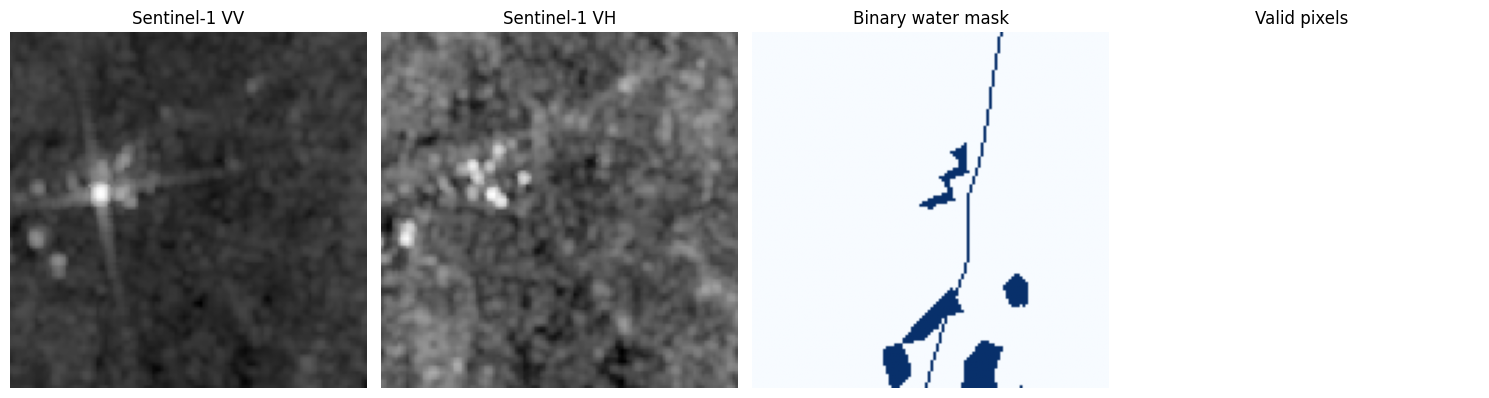

Image min/max: 0.11374836 1.4872406
Mask classes: [0 1] Valid fraction: 1.0


In [29]:
x_sample, y_sample, valid_sample = next(iter(make_dataset(train_names[:1], training=False)))
x_sample = x_sample[0].numpy()
y_sample = np.argmax(y_sample[0].numpy(), axis=-1)
valid_sample = valid_sample[0, ..., 0].numpy()

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(x_sample[..., 0], cmap="gray"); ax[0].set_title("Sentinel-1 VV")
ax[1].imshow(x_sample[..., 1], cmap="gray"); ax[1].set_title("Sentinel-1 VH")
ax[2].imshow(y_sample, cmap="Blues", vmin=0, vmax=1); ax[2].set_title("Binary water mask")
ax[3].imshow(valid_sample, cmap="gray", vmin=0, vmax=1); ax[3].set_title("Valid pixels")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()
print("Image min/max:", x_sample.min(), x_sample.max())
print("Mask classes:", np.unique(y_sample), "Valid fraction:", valid_sample.mean())

## Cell 10 — Define U-Net and categorical focal loss

The network uses a U-Net encoder/decoder with skip connections, 2-channel input and 2-class softmax output. The focal loss follows the paper's stated α=0.25 and γ=2.0. Validity weights mask no-data pixels out of the loss.

In [30]:
from tensorflow.keras import layers, models, regularizers

def conv_block(x, filters, dropout_rate=0.0, weight_decay=1e-4, pool=True):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu",
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(weight_decay))(x)
    x = layers.Conv2D(filters, 3, padding="same", activation="relu",
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(weight_decay))(x)
    skip = x
    if dropout_rate > 0:
        x = layers.Dropout(dropout_rate)(x)
    if pool:
        x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    return x, skip

def build_unet(input_shape=(128, 128, 2), n_classes=2, start_filters=32,
               n_blocks=6, dropout_rate=0.30, weight_decay=1e-4):
    inputs = layers.Input(shape=input_shape)
    x = inputs
    skips = []
    filters = start_filters

    # n_blocks includes the bottleneck block; with 128x128, six blocks are valid.
    for level in range(n_blocks - 1):
        x, skip = conv_block(
            x, filters, dropout_rate=dropout_rate,
            weight_decay=weight_decay, pool=True
        )
        skips.append(skip)
        filters *= 2

    x, _ = conv_block(
        x, filters, dropout_rate=dropout_rate,
        weight_decay=weight_decay, pool=False
    )

    for skip in reversed(skips):
        filters //= 2
        x = layers.Conv2DTranspose(filters, 3, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skip])
        x = layers.Conv2D(filters, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu",
                          kernel_initializer="he_normal")(x)

    outputs = layers.Conv2D(n_classes, 1, activation="softmax", dtype="float32")(x)
    return models.Model(inputs, outputs, name="sentinel1_unet")

def categorical_focal_loss(alpha=0.25, gamma=2.0):
    def loss(y_true, y_pred):
        eps = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
        p_t = tf.reduce_sum(y_true * y_pred, axis=-1)
        per_pixel_loss = -alpha * tf.pow(1.0 - p_t, gamma) * tf.math.log(p_t)
        return tf.expand_dims(per_pixel_loss, axis=-1)  # match validity-weight shape (B,H,W,1)
    return loss

with tf.device("/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0"):
    model = build_unet(
        input_shape=(TILE_SIZE, TILE_SIZE, N_CHANNELS),
        n_classes=N_CLASSES,
        start_filters=START_FILTERS,
        n_blocks=N_BLOCKS,
        dropout_rate=DROPOUT,
        weight_decay=WEIGHT_DECAY
    )

model.summary()
print("Trainable parameters:", model.count_params())

Model: "sentinel1_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 2)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        608 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ dropout_1[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ dropout_2[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 16, 16,    │          0 │ conv2d_7[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 256) │          0 │ dropout_3[0][0] 

 Total params: 8,630,242 (32.92 MB)

 Trainable params: 8,630,242 (32.92 MB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 8630242


## Cell 11 — Compile and train with checkpoints / early stopping

In [31]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=categorical_focal_loss(alpha=0.25, gamma=2.0),
    metrics=[tf.keras.metrics.CategoricalAccuracy(name="pixel_accuracy")]
)

OUT_DIR = "/content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
BEST_MODEL_PATH = os.path.join(OUT_DIR, "sentinel1_unet_best.keras")
BEST_WEIGHTS_PATH = os.path.join(OUT_DIR, "sentinel1_unet_best.weights.h5")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=7, restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.CSVLogger(os.path.join(OUT_DIR, "training_log.csv"))
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)
model.save(BEST_MODEL_PATH)
model.save_weights(BEST_WEIGHTS_PATH)
print("Saved best model:", BEST_MODEL_PATH)

Epoch 1/20
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 0.0912 - pixel_accuracy: 0.7925
Epoch 1: val_loss improved from None to 0.03337, saving model to /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs/sentinel1_unet_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs/sentinel1_unet_best.keras
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 145s 93ms/step - loss: 0.0521 - pixel_accuracy: 0.8062 - val_loss: 0.0334 - val_pixel_accuracy: 0.8117 - learning_rate: 0.0010
Epoch 2/20
1185/1186 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 0.0339 - pixel_accuracy: 0.8140
Epoch 2: val_loss improved from 0.03337 to 0.03160, saving model to /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs/sentinel1_unet_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs/sentinel1_unet_best.keras
1186/1186 ━━━━━━━━━━━━━━━━━━━━ 81s 69ms/step - loss: 0.0329 - pixel_accuracy: 0.8167 - val_loss: 

## Cell 12 — Plot training curves

,loss,pixel_accuracy,val_loss,val_pixel_accuracy,learning_rate
15,0.027082,0.821143,0.026932,0.820210,0.001
16,0.026910,0.822232,0.028371,0.812923,0.001
17,0.026718,0.822721,0.027106,0.816622,0.001
18,0.026718,0.819788,0.025810,0.825934,0.001
19,0.026201,0.825736,0.026357,0.818916,0.001


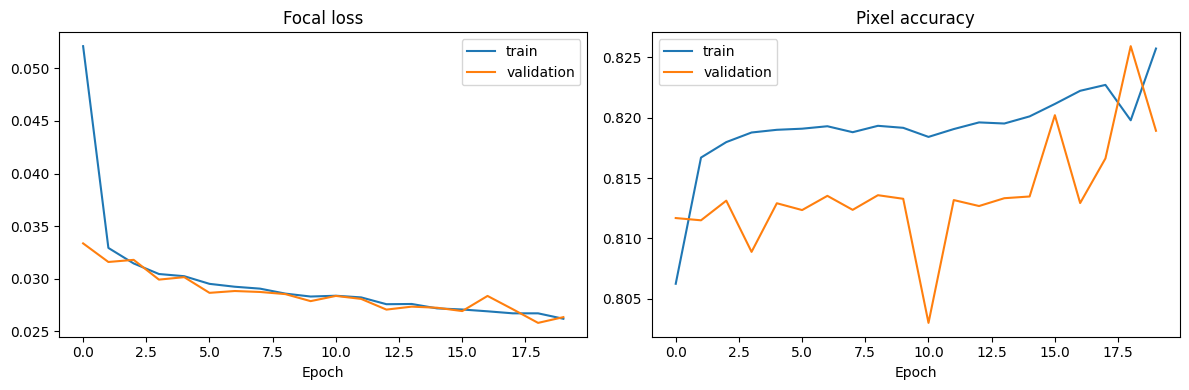

In [32]:
hist = pd.DataFrame(history.history)
display(hist.tail())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["loss"], label="train")
ax[0].plot(hist["val_loss"], label="validation")
ax[0].set_title("Focal loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
if "pixel_accuracy" in hist:
    ax[1].plot(hist["pixel_accuracy"], label="train")
    ax[1].plot(hist["val_pixel_accuracy"], label="validation")
    ax[1].set_title("Pixel accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout()
plt.show()

## Cell 13 — Evaluate once on the held-out test set

Metrics are computed over **valid pixels only** and include overall accuracy plus water-class precision, recall, F1 and IoU. This is more informative than accuracy alone when non-water pixels dominate.

In [33]:
# Reload best checkpoint if present.
if os.path.exists(BEST_MODEL_PATH):
    model = tf.keras.models.load_model(
        BEST_MODEL_PATH,
        custom_objects={"loss": categorical_focal_loss(alpha=0.25, gamma=2.0)},
        compile=False
    )

all_true, all_pred = [], []
for xb, yb, wb in test_ds:
    probs = model.predict(xb, verbose=0)
    pred = np.argmax(probs, axis=-1)
    true = np.argmax(yb.numpy(), axis=-1)
    valid = wb.numpy()[..., 0] > 0.5
    all_true.append(true[valid])
    all_pred.append(pred[valid])

y_true = np.concatenate(all_true)
y_pred = np.concatenate(all_pred)

metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "water_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
    "water_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
    "water_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    "water_iou": jaccard_score(y_true, y_pred, pos_label=1, zero_division=0),
    "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
}
print(json.dumps(metrics, indent=2))
print("\nConfusion matrix (rows=true, columns=predicted):\n", confusion_matrix(y_true, y_pred))
print("\nClassification report:\n", classification_report(
    y_true, y_pred, target_names=["non-water", "water"], zero_division=0
))

pd.DataFrame([metrics]).to_csv(os.path.join(OUT_DIR, "test_metrics.csv"), index=False)
print("Saved metrics:", os.path.join(OUT_DIR, "test_metrics.csv"))

{
  "accuracy": 0.8416808773253056,
  "water_precision": 0.7695559773543038,
  "water_recall": 0.6000926956924764,
  "water_f1": 0.6743406977637828,
  "water_iou": 0.5086832616994854,
  "macro_f1": 0.784880136696594,
  "weighted_f1": 0.8350319195698912
}

Confusion matrix (rows=true, columns=predicted):
 [[6584976  476891]
 [1061292 1592553]]

Classification report:
               precision    recall  f1-score   support

   non-water       0.86      0.93      0.90   7061867
       water       0.77      0.60      0.67   2653845

    accuracy                           0.84   9715712
   macro avg       0.82      0.77      0.78   9715712
weighted avg       0.84      0.84      0.84   9715712

Saved metrics: /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs/test_metrics.csv


## Cell 14 — Visualize held-out test predictions

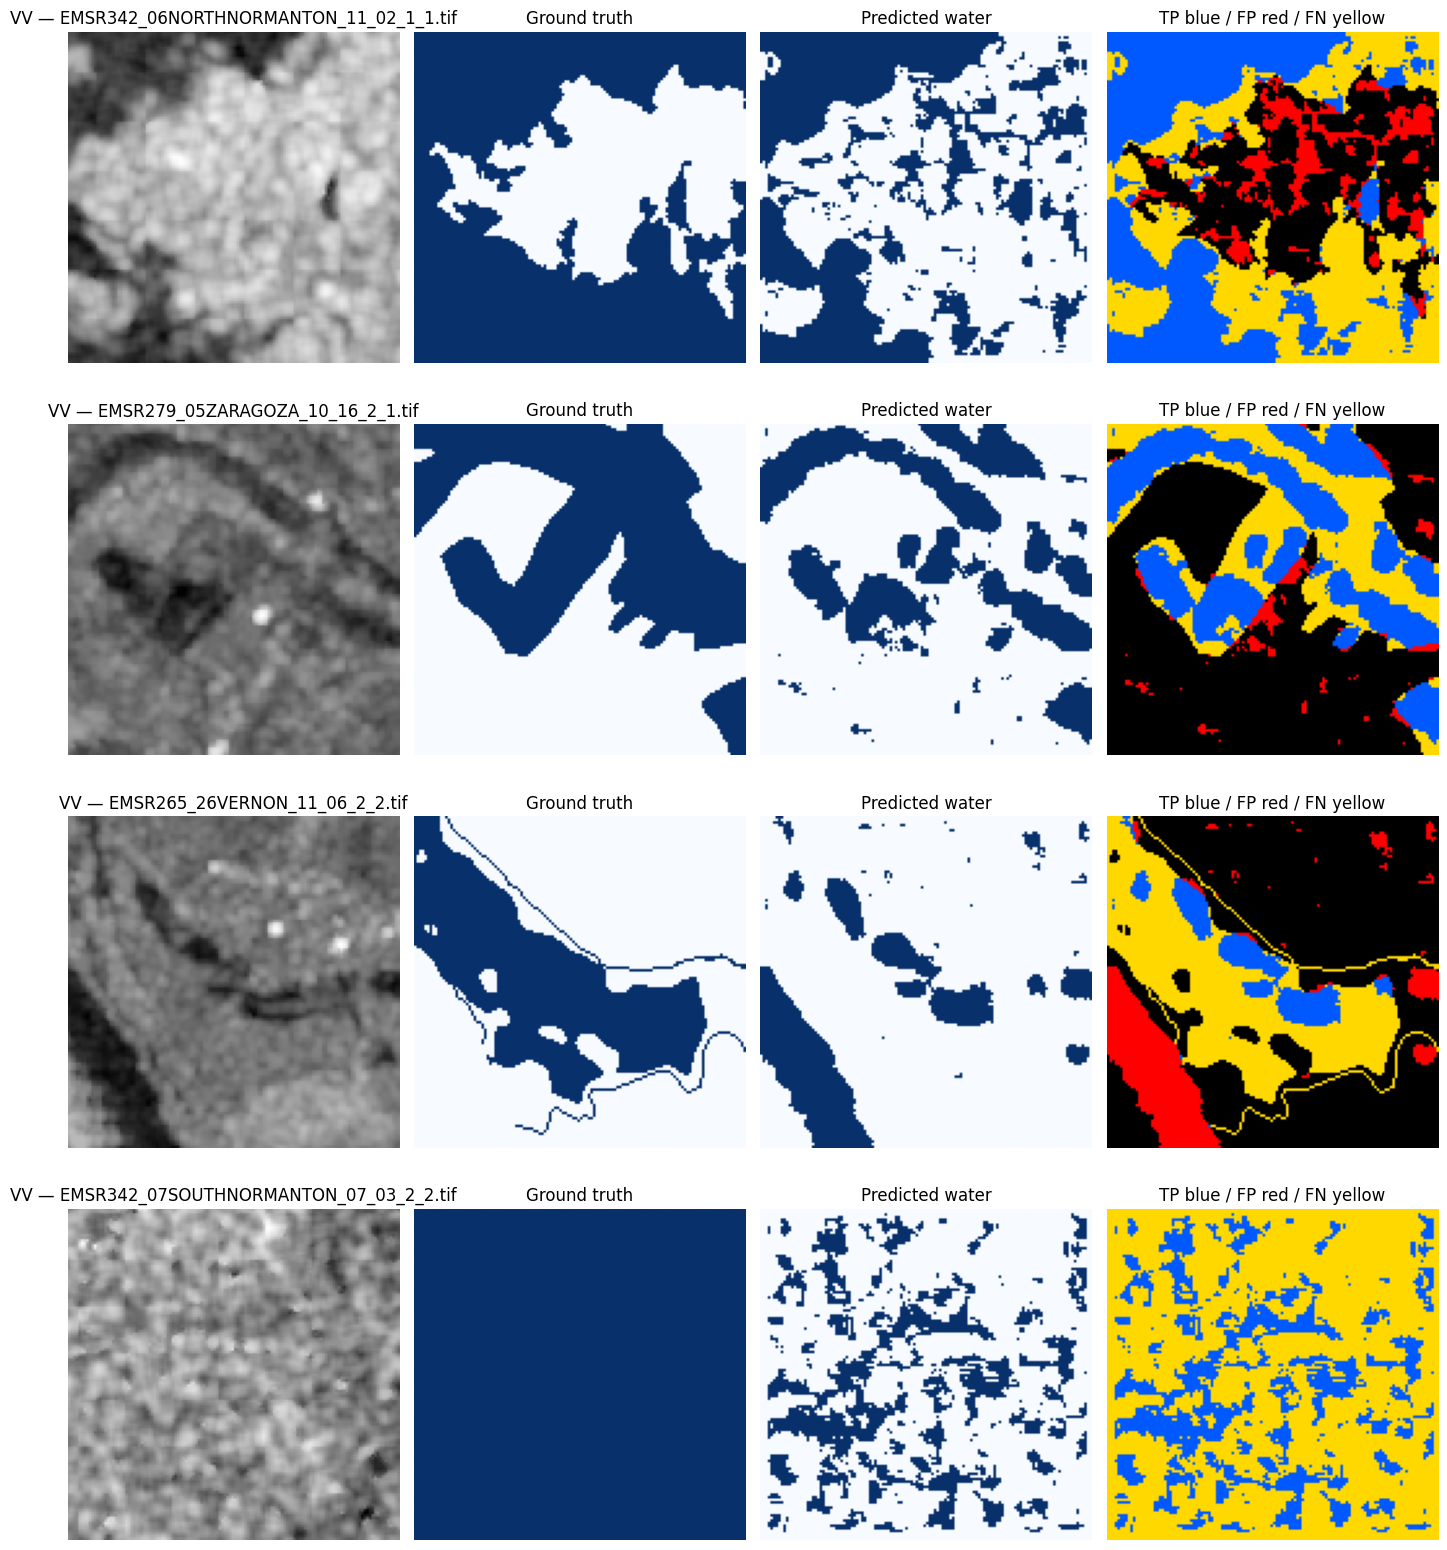

In [34]:
def show_test_predictions(names, n=4):
    chosen = names[:min(n, len(names))]
    fig, axes = plt.subplots(len(chosen), 4, figsize=(14, 4 * len(chosen)))
    if len(chosen) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, name in enumerate(chosen):
        x = read_s1_image(image_map[name])
        y, valid = read_s1_mask(mask_map[name])
        p = model.predict(x[None, ...], verbose=0)[0, ..., 1]
        pred = (p >= 0.5).astype(np.uint8)

        axes[i, 0].imshow(x[..., 0], cmap="gray"); axes[i, 0].set_title(f"VV — {name}")
        axes[i, 1].imshow(y, cmap="Blues", vmin=0, vmax=1); axes[i, 1].set_title("Ground truth")
        axes[i, 2].imshow(pred, cmap="Blues", vmin=0, vmax=1); axes[i, 2].set_title("Predicted water")
        # TP blue, FP red, FN yellow, TN dark
        overlay = np.zeros((*y.shape, 3), dtype=np.float32)
        overlay[(pred == 1) & (y == 1)] = [0.0, 0.35, 1.0]  # TP
        overlay[(pred == 1) & (y == 0)] = [1.0, 0.0, 0.0]   # FP
        overlay[(pred == 0) & (y == 1)] = [1.0, 0.85, 0.0]  # FN
        overlay[~valid] = [0.5, 0.5, 0.5]
        axes[i, 3].imshow(overlay); axes[i, 3].set_title("TP blue / FP red / FN yellow")
        for a in axes[i]: a.axis("off")
    plt.tight_layout()
    plt.show()

show_test_predictions(test_names, n=4)

## Cell 15 — Save experiment configuration and split manifest

Keep these files for reproducibility and for comparing later experiments. The paper's reported Sentinel-1 test accuracy (83.61%) and weighted F1 (0.8327) are **reference results from the publication**, not expected guaranteed outcomes for this run.

In [35]:
config = {
    "dataset": "STURM-Flood Sentinel-1",
    "seed": SEED,
    "tile_size": TILE_SIZE,
    "channels": ["VV", "VH"],
    "classes": {"0": "non-water", "1": "water"},
    "normalization_db_range": NORMALIZE_DB_RANGE,
    "start_filters": START_FILTERS,
    "n_blocks": N_BLOCKS,
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "loss": "categorical focal cross-entropy, alpha=0.25, gamma=2.0",
    "split_seed": SEED,
    "n_valid_pairs": len(valid_names),
    "n_train": len(train_names),
    "n_validation": len(val_names),
    "n_test": len(test_names),
    "test_metrics": metrics
}
with open(os.path.join(OUT_DIR, "experiment_config.json"), "w") as f:
    json.dump(config, f, indent=2)
split_df.to_csv(os.path.join(OUT_DIR, "split_manifest.csv"), index=False)

print("Outputs saved to:", OUT_DIR)
print("Files:", os.listdir(OUT_DIR))

Outputs saved to: /content/drive/MyDrive/STURM-Flood/baseline_sentinel1_outputs
Files: ['training_log.csv', 'sentinel1_unet_best.keras', 'sentinel1_unet_best.weights.h5', 'test_metrics.csv', 'experiment_config.json', 'split_manifest.csv']


In [36]:
import tensorflow as tf
import os

MODEL_PATH = (
    "/content/drive/MyDrive/STURM-Flood/"
    "baseline_sentinel1_outputs/sentinel1_unet_best.keras"
)

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")
print("Model parameters:", model.count_params())

Model loaded successfully!
Model parameters: 8630242
